# Medication block EDA (Paulo)

Scope: the 23 drug columns (`metformin` → `metformin-pioglitazone`) + `readmitted`.

## Step 1 — Load & sanity check

Load with `na_values="?"` and `keep_default_na=False`, confirm the 101,766 × 50 shape, and check the value counts of the drug columns.

In [1]:
import pandas as pd

# keep_default_na=False so the text "None" (test not done) is not read as NaN
df = pd.read_csv("../data/raw/diabetic_data.csv", na_values="?", keep_default_na=False, low_memory=False)
assert df.shape == (101766, 50), df.shape
print("shape:", df.shape)
print("encounters:", df["encounter_id"].nunique(), "| patients:", df["patient_nbr"].nunique())

shape: (101766, 50)
encounters: 101766 | patients: 71518


In [2]:
drug_cols = df.loc[:, "metformin":"metformin-pioglitazone"].columns.tolist()
assert len(drug_cols) == 23
print("levels found in drug columns:", sorted(pd.unique(df[drug_cols].values.ravel())))
print("missing values in drug columns:", df[drug_cols].isna().sum().sum())

levels found in drug columns: ['Down', 'No', 'Steady', 'Up']


missing values in drug columns: 0


In [3]:
# Value counts per drug, one row per drug, ordered by number of encounters taking it
counts = (
    df[drug_cols].apply(lambda s: s.value_counts()).T
    .reindex(columns=["No", "Steady", "Up", "Down"]).fillna(0).astype(int)
)
counts["taking"] = counts[["Steady", "Up", "Down"]].sum(axis=1)
counts.sort_values("taking", ascending=False)

,No,Steady,Up,Down,taking
insulin,47383,30849,11316,12218,54383
metformin,81778,18346,1067,575,19988
glipizide,89080,11356,770,560,12686
glyburide,91116,9274,812,564,10650
pioglitazone,94438,6976,234,118,7328
rosiglitazone,95401,6100,178,87,6365
glimepiride,96575,4670,327,194,5191
repaglinide,100227,1384,110,45,1539
glyburide-metformin,101060,692,8,6,706
nateglinide,101063,668,24,11,703


In [4]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

### Step 1 — notes

- **Load is clean:** 101,766 encounters × 50 columns, 71,518 unique patients, as documented. The comma separator and `keep_default_na=False` are correct; `low_memory=False` removes the mixed-type warning on `payer_code`.
- **Drug columns are tidy:** all 23 use only `No` / `Steady` / `Up` / `Down` and have no missing values, so they need no cleaning.
- **Usage is very uneven:** insulin is used in 54,383 encounters and metformin in 19,988, while 9 drugs have fewer than 40 users and `examide` / `citoglipton` have none. Target: `<30` = 11,357 encounters (11.2%).

## Step 2 — Profile the medication block

`ydata-profiling` on the drug columns + `readmitted` only. Report saved to `reports/generated/`.

In [5]:
from ydata_profiling import ProfileReport

C:\Users\felic\AppData\Local\Temp\ipykernel_29836\44057814.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [6]:
med = df[drug_cols + ["readmitted"]]

In [7]:
profile = ProfileReport(med, title="Medication block — diabetic_data", explorative=True)
profile.to_file("../reports/generated/profile-report-medications.html")

C:\Users\felic\OneDrive\Documentos\NOVA IMS\2 - Semester\Enterprise Data Science Bootcamp\Project\enterprise-data-science-bootcamp\.venv\Lib\site-packages\ydata_profiling\utils\dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

  8%|▊         | 2/24 [00:01<00:21,  1.02it/s]

100%|██████████| 24/24 [00:01<00:00, 12.24it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [8]:
# Alerts raised by the profile, grouped by type
alerts = pd.DataFrame(
    [(a.alert_type.name, a.column_name) for a in profile.get_description().alerts],
    columns=["alert", "column"],
)
for alert, cols in alerts.groupby("alert")["column"]:
    print(f"{alert} ({len(cols)}): {list(cols)}")

not_flagged = [c for c in drug_cols if c not in set(alerts["column"])]
print("Drug columns with no alert:", not_flagged)
print("Duplicate rows in this 24-column subset:", med.duplicated().sum())

CONSTANT (2): ['examide', 'citoglipton']
DUPLICATES (1): [None]
IMBALANCE (20): ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
Drug columns with no alert: ['insulin']
Duplicate rows in this 24-column subset: 99559


In [9]:
# Same picture as numbers: share of the most frequent level and number of encounters taking the drug
summary = pd.DataFrame({
    "n_levels": med[drug_cols].nunique(),
    "top_level": med[drug_cols].mode().iloc[0],
    "top_share_%": (med[drug_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(2),
    "n_taking": (med[drug_cols] != "No").sum(),
    "n_missing": med[drug_cols].isna().sum(),
}).sort_values("n_taking")
summary

,n_levels,top_level,top_share_%,n_taking,n_missing
examide,1,No,100.00,0,0
citoglipton,1,No,100.00,0,0
glimepiride-pioglitazone,2,No,100.00,1,0
acetohexamide,2,No,100.00,1,0
metformin-pioglitazone,2,No,100.00,1,0
metformin-rosiglitazone,2,No,100.00,2,0
troglitazone,2,No,100.00,3,0
glipizide-metformin,2,No,99.99,13,0
tolbutamide,2,No,99.98,23,0
miglitol,4,No,99.96,38,0


In [10]:
med["readmitted"].value_counts(normalize=True).mul(100).round(2)

readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

### Step 2 — notes

- **Zero variance:** `examide` and `citoglipton` are flagged CONSTANT (100% `No`). There is nothing to learn from them, so they are certain drops.
- **High imbalance:** 20 of the 23 drug columns are flagged IMBALANCE. Insulin is the only one with no alert (46.6% `No`). That flag alone isn't enough to drop a column, because metformin (~20k users) is flagged too. Step 3 needs a usage-count threshold. The 7 columns with 3 or fewer users are effectively empty.
- **No missing values** in any drug column. The DUPLICATES alert (99,559 rows) is expected: with only 24 categorical columns, most encounters share the same pattern, so it is not a data-quality issue. Target in this file: `<30` = 11.16%, `>30` = 34.93%, `NO` = 53.91%.

## Step 3 — Drop list

Rule: keep a drug if at least `THRESHOLD` of encounters take it (value != `"No"`); drop it otherwise, and flag columns with a single value as constant.

In [11]:
THRESHOLD = 0.01  # minimum share of encounters taking the drug

taking = df[drug_cols] != "No"
drop_list = pd.DataFrame({
    "n_levels": df[drug_cols].nunique(),
    "n_taking": taking.sum(),
    "pct_taking": (taking.mean() * 100).round(2),
}).sort_values("n_taking", ascending=False)

drop_list["decision"] = "keep"
drop_list.loc[drop_list["n_taking"] < THRESHOLD * len(df), "decision"] = "drop_rare"
drop_list.loc[drop_list["n_levels"] == 1, "decision"] = "drop_constant"
print(f"Threshold: {THRESHOLD:.0%} of {len(df):,} encounters = {THRESHOLD * len(df):,.0f} encounters")
drop_list

Threshold: 1% of 101,766 encounters = 1,018 encounters


,n_levels,n_taking,pct_taking,decision
insulin,4,54383,53.44,keep
metformin,4,19988,19.64,keep
glipizide,4,12686,12.47,keep
glyburide,4,10650,10.47,keep
pioglitazone,4,7328,7.20,keep
rosiglitazone,4,6365,6.25,keep
glimepiride,4,5191,5.10,keep
repaglinide,4,1539,1.51,keep
glyburide-metformin,4,706,0.69,drop_rare
nateglinide,4,703,0.69,drop_rare


In [12]:
MED_KEEP = drop_list.index[drop_list["decision"] == "keep"].tolist()
MED_DROP = drop_list.index[drop_list["decision"] != "keep"].tolist()
print(f"MED_KEEP = {MED_KEEP}  # {len(MED_KEEP)} columns")
print(f"MED_DROP = {MED_DROP}  # {len(MED_DROP)} columns")

MED_KEEP = ['insulin', 'metformin', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'glimepiride', 'repaglinide']  # 8 columns
MED_DROP = ['glyburide-metformin', 'nateglinide', 'acarbose', 'chlorpropamide', 'tolazamide', 'miglitol', 'tolbutamide', 'glipizide-metformin', 'troglitazone', 'metformin-rosiglitazone', 'acetohexamide', 'glimepiride-pioglitazone', 'metformin-pioglitazone', 'examide', 'citoglipton']  # 15 columns


### Step 3 — notes

- **Rule:** keep a drug if at least 1% of encounters take it (`THRESHOLD = 0.01`, about 1,018 encounters). Below that, a drug is too rare to estimate a reliable readmission rate per level. Columns with a single value are dropped as constant.
- **Result:** 8 kept (`insulin`, `metformin`, `glipizide`, `glyburide`, `pioglitazone`, `rosiglitazone`, `glimepiride`, `repaglinide`) and 15 dropped (13 `drop_rare` + `examide` / `citoglipton` `drop_constant`). The cutoff falls in a clear gap: the smallest kept drug, `repaglinide`, has 1,539 users and the largest dropped one, `glyburide-metformin`, has 706.
- **Open point:** `glyburide-metformin` (706), `nateglinide` (703) and `acarbose` (308) are dropped as individual columns but are not lost entirely, since Step 5's `n_meds_taken` / `any_oral_agent` can still count them. `MED_KEEP` / `MED_DROP` are lists only: nothing is removed from `df` yet.

## Step 4 — Medication vs target

For each drug in `MED_KEEP`: the <30-day readmission rate by level (`No` / `Steady` / `Up` / `Down`), with a 95% Wilson confidence interval.

A drug gets a chart only if its rate differs across levels in a chi-square test at `ALPHA / len(MED_KEEP)` (Bonferroni, because we test 8 drugs at once).

In [13]:
# ydata-profiling (Step 2) switches matplotlib to the non-interactive "agg" backend; switch back
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

ALPHA = 0.05
LEVELS = ["No", "Steady", "Up", "Down"]
y = (df["readmitted"] == "<30").astype(int)
BASE_RATE = y.mean()


def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n; returns (low, high)."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


rows = []
for drug in MED_KEEP:
    g = y.groupby(df[drug]).agg(n="size", n_lt30="sum").reindex(LEVELS)
    for level, (n, k) in g.iterrows():
        low, high = wilson_ci(k, n)
        rows.append((drug, level, n, k, k / n, low, high))
rates = pd.DataFrame(rows, columns=["drug", "level", "n", "n_lt30", "rate", "ci_low", "ci_high"])

print(f"Base <30 rate: {BASE_RATE:.2%}")
# Rate (%) by level, with group sizes alongside
wide = rates.pivot(index="drug", columns="level", values="rate").loc[MED_KEEP, LEVELS].mul(100).round(1)
sizes = rates.pivot(index="drug", columns="level", values="n").loc[MED_KEEP, LEVELS].add_prefix("n_")
wide.join(sizes)

Base <30 rate: 11.16%


level,No,Steady,Up,Down,n_No,n_Steady,n_Up,n_Down
drug,,,,,,,,
insulin,10.0,11.1,13.0,13.9,47383,30849,11316,12218
metformin,11.5,9.7,8.2,12.0,81778,18346,1067,575
glipizide,11.1,11.2,12.9,15.2,89080,11356,770,560
glyburide,11.2,10.7,10.5,9.2,91116,9274,812,564
pioglitazone,11.2,10.4,12.4,15.3,94438,6976,234,118
rosiglitazone,11.2,10.5,10.7,5.7,95401,6100,178,87
glimepiride,11.2,10.0,11.3,12.9,96575,4670,327,194
repaglinide,11.1,13.2,18.2,6.7,100227,1384,110,45


In [14]:
# One chi-square test per drug: does the <30 rate depend on the level?
tests = pd.DataFrame(
    [(d, chi2_contingency(pd.crosstab(df[d], y))[1]) for d in MED_KEEP],
    columns=["drug", "p_value"],
).set_index("drug")
tests["rate_taking_%"] = [y[df[d] != "No"].mean() * 100 for d in tests.index]
tests["rate_not_taking_%"] = [y[df[d] == "No"].mean() * 100 for d in tests.index]
tests["chart"] = tests["p_value"] < ALPHA / len(MED_KEEP)
print(f"Bonferroni cut-off: p < {ALPHA / len(MED_KEEP):.4f}")
tests.sort_values("p_value").round({"rate_taking_%": 1, "rate_not_taking_%": 1}).style.format({"p_value": "{:.1e}"})

Bonferroni cut-off: p < 0.0063


,p_value,rate_taking_%,rate_not_taking_%,chart
drug,,,,
insulin,4.0e-41,12.100000,10.000000,True
metformin,1.1e-12,9.700000,11.500000,True
repaglinide,7.3e-03,13.300000,11.100000,False
glipizide,9.3e-03,11.400000,11.100000,False
glimepiride,7.3e-02,10.200000,11.200000,False
pioglitazone,9.4e-02,10.600000,11.200000,False
rosiglitazone,1.4e-01,10.400000,11.200000,False
glyburide,2.0e-01,10.600000,11.200000,False


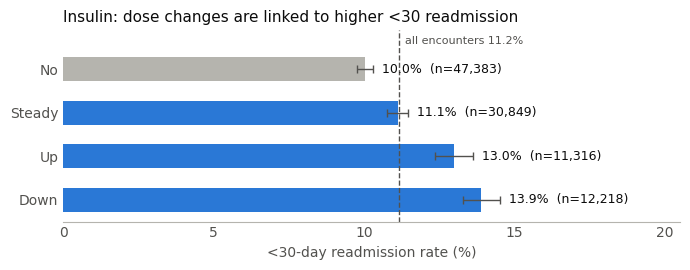

In [15]:
BAR, CONTEXT, INK, MUTED = "#2a78d6", "#b5b4ae", "#0b0b0b", "#52514e"


def plot_drug_rates(drug, title):
    """Horizontal bar chart of the <30 rate by level for one drug, with 95% CIs and the base rate."""
    d = rates[rates["drug"] == drug].set_index("level").loc[LEVELS[::-1]]
    fig, ax = plt.subplots(figsize=(7, 2.8))
    colors = [CONTEXT if lvl == "No" else BAR for lvl in d.index]
    ax.barh(d.index, d["rate"] * 100, height=0.55, color=colors)
    ax.errorbar(d["rate"] * 100, d.index,
                xerr=[(d["rate"] - d["ci_low"]) * 100, (d["ci_high"] - d["rate"]) * 100],
                fmt="none", ecolor=MUTED, elinewidth=1, capsize=3)
    for lvl, r in d.iterrows():
        ax.text(r["ci_high"] * 100 + 0.3, lvl, f"{r['rate']:.1%}  (n={r['n']:,.0f})",
                va="center", fontsize=9, color=INK)
    ax.axvline(BASE_RATE * 100, color=MUTED, linestyle="--", linewidth=1)
    ax.set_ylim(-0.5, len(d) - 0.1)  # headroom above the top bar for the base-rate label
    ax.text(BASE_RATE * 100 + 0.2, len(d) - 0.35, f"all encounters {BASE_RATE:.1%}",
            ha="left", va="center", fontsize=8, color=MUTED)
    ax.set_xlim(0, max(d["ci_high"]) * 100 + 6)
    ax.xaxis.set_major_locator(plt.MultipleLocator(5))
    ax.set_xlabel("<30-day readmission rate (%)", color=MUTED)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.tick_params(colors=MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(CONTEXT)
    plt.tight_layout()
    plt.show()


plot_drug_rates("insulin", "Insulin: dose changes are linked to higher <30 readmission")

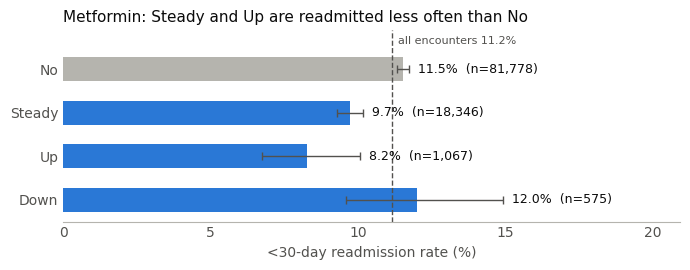

In [16]:
plot_drug_rates("metformin", "Metformin: Steady and Up are readmitted less often than No")

In [17]:
# Sensitivity check: drop expired/hospice discharges (they cannot be readmitted) and recompute.
# Works on a filtered copy; df, y and rates are left unchanged.
EXPIRED_HOSPICE_IDS = [11, 13, 14, 19, 20, 21]  # discharge_disposition_id
expired = df["discharge_disposition_id"].isin(EXPIRED_HOSPICE_IDS)
df_alive = df.loc[~expired].copy()
y_alive = y[~expired]

print(f"Removed: {expired.sum():,} encounters ({expired.mean():.1%}), <30 rate among them: {y[expired].mean():.2%}")
print(f"Base <30 rate: {BASE_RATE:.2%} original -> {y_alive.mean():.2%} without")

sens = []
for drug in ["insulin", "metformin"]:
    original = rates[rates["drug"] == drug].set_index("level")["rate"]
    without = y_alive.groupby(df_alive[drug]).mean()
    for level in LEVELS:
        sens.append((drug, level, original[level] * 100, without[level] * 100))
sensitivity = pd.DataFrame(sens, columns=["drug", "level", "original %", "without %"]).set_index("drug").round(2)
sensitivity

Removed: 2,423 encounters (2.4%), <30 rate among them: 1.77%
Base <30 rate: 11.16% original -> 11.39% without


,level,original %,without %
drug,,,
insulin,No,10.04,10.21
insulin,Steady,11.13,11.37
insulin,Up,12.99,13.33
insulin,Down,13.90,14.22
metformin,No,11.52,11.79
metformin,Steady,9.71,9.78
metformin,Up,8.25,8.28
metformin,Down,12.00,12.02


### Step 4 — notes

- **Insulin is the strongest signal** (p = 4e-41). The <30 rate rises from 10.0% (`No`) to 11.1% (`Steady`), 13.0% (`Up`) and 13.9% (`Down`). Any dose change carries about +3 pp over not taking insulin, which supports `insulin_status` and `n_dose_changes` in Step 5.
- **Metformin goes the other way** (p = 1e-12): `Steady` 9.7% and `Up` 8.2% vs 11.5% for `No`. This is probably confounding, not a protective effect: metformin is usually withheld from sicker patients (kidney or heart failure), who are readmitted more anyway. Say so in the presentation.
- **The other 6 drugs don't pass the Bonferroni cut-off** (p < 0.0063). `repaglinide` (p = 0.007) and `glipizide` (p = 0.009) come close, but their striking rates (repaglinide `Up` 18.2%, glipizide `Down` 15.2%) sit on groups of fewer than 800 encounters with wide intervals. They stay in `MED_KEEP` as columns but get no chart.
- **Caveat:** the tests treat the 101,766 encounters as independent, but they come from 71,518 patients, so the p-values are optimistic. The ranking (insulin, then metformin, then the rest) is what matters here.
- Expired/hospice discharges not yet removed; re-checked without them (sensitivity cell) and the patterns hold. Rates move up by ~0.2–0.3 pp.